# LAB 10 — Fine-tuning và đánh giá Extractive QA

Notebook chạy §§14, 17–25 và kiểm tra ứng dụng §27. Chạy từ thư mục chứa `qa_model.py`. Hồ sơ mặc định `quick` tạo lại kết quả nộp. Hồ sơ `full` dùng toàn bộ dữ liệu train và hai nửa official dev theo bài viết, cần nhiều bộ nhớ và thời gian hơn. Các kết quả xuất từ hồ sơ `full` được giữ trong thư mục riêng.

## 14. Experiment 1 — Context Length

Ba lần huấn luyện dùng cùng checkpoint BERT gốc, cùng seed, câu hỏi, context, batch size, số epoch, stride và optimizer. Chỉ đổi `max_length` giữa 128, 256 và 384. Stride 64 hợp lệ ở cả ba độ dài, khác với ví dụ riêng §15 ở notebook tokenizer. Số cửa sổ và số lượt cập nhật có thể đổi theo độ dài, nên báo cáo cả số feature và thời gian. Các kết quả trên test dùng checkpoint có F1 validation cao nhất của từng cấu hình. Mô hình 384 được ấn định trước làm hệ thống chính cho §§20–27.

In [1]:
import hashlib
import json
import os
import platform
import re
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

from qa_model import (
    MODEL_ID, MODEL_REVISION, Example, ExtractiveBert, Settings, baseline_predict,
    content_words, exact_match, fit, load_squad, load_tokenizer, make_features,
    normalized_tokens, predict_examples, save_run, score_predictions, token_f1,
)
from document_qa import DEMO_DOCUMENT, DEMO_QUESTIONS, answer_questions

root = Path.cwd()
assert (root / "qa_model.py").is_file(), "Open the notebook from inside lab10."
work = Path(os.environ.get("LAB10_WORK", root / ".lab10")).resolve()
profile = os.getenv("LAB10_PROFILE", "quick")
counts = {"quick": (4200, 600, 1200), "full": (None, None, None)}[profile]
export_dir = root if profile == "quick" else work / "full_results"
export_dir.mkdir(parents=True, exist_ok=True)
use_saved_runs = os.getenv("LAB10_REUSE_RUNS", "0") == "1"
model_source = os.getenv("LAB10_MODEL_SOURCE") or MODEL_ID
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(6, os.cpu_count() or 1))
    torch.set_num_interop_threads(1)
config = Settings()
lengths = (128, 256, 384)
splits = load_squad(work / "data", *counts, seed=config.seed)
tokenizer = load_tokenizer(model_source)
signature = hashlib.sha256(
    "\n".join(item.id for split in splits.values() for item in split).encode()
).hexdigest()
cpu_info = Path("/proc/cpuinfo")
cpu_match = re.search(r"model name\s*:\s*(.+)", cpu_info.read_text()) if cpu_info.is_file() else None
hardware = torch.cuda.get_device_name() if device.type == "cuda" else (
    cpu_match[1] if cpu_match else (platform.processor() or platform.machine())
)
meta = {"data_signature": signature, "model_id": MODEL_ID, "revision": MODEL_REVISION,
        "device": device.type, "hardware": hardware, "threads": torch.get_num_threads(),
        "profile": profile, "split_sizes": {key: len(items) for key, items in splits.items()}}
run_root = work / ("runs" if profile == "quick" else "runs_full")
assert set(item.title for item in splits["validation"]).isdisjoint(
    item.title for item in splits["test"]
)
print(meta)

{'data_signature': '0a4549435c8f85a8b24e10019b019a7be627304605b4f36fd025fd2a4041e7ee', 'model_id': 'google/bert_uncased_L-2_H-128_A-2', 'revision': '30b0a37ccaaa32f332884b96992754e246e48c5f', 'device': 'cpu', 'hardware': 'AMD EPYC 9V74 80-Core Processor', 'threads': 6, 'profile': 'quick', 'split_sizes': {'train': 4200, 'validation': 600, 'test': 1200}}


## 17. Experiment 2 — Pretrained QA Model

`qa_model.py` chạy encoder BERT, áp dụng lớp tuyến tính hai kênh cho mỗi token và tính trung bình hai cross-entropy. Padding, câu hỏi và separator bị loại khỏi tập vị trí ứng viên. Cửa sổ không chứa trọn gold nhận cặp nhãn `[CLS]`. Khi suy luận SQuAD v1.1, mô hình tìm cặp biên hợp lệ có điểm cao nhất trong từng cửa sổ rồi so điểm chênh so với `[CLS]` giữa các cửa sổ. `[CLS]` tại đây hỗ trợ xếp hạng cửa sổ.

Loss được lấy trung bình theo số feature. EM và F1 tính theo từng câu hỏi sau khi gộp tất cả cửa sổ. Thời gian train chỉ cộng thời gian các epoch tối ưu, bỏ thời gian tokenization và đánh giá.

In [2]:
results, histories, test_predictions = [], {}, {}
eval_rows = []
test = splits["test"]

def build_features(items, settings):
    return make_features(items, tokenizer, settings.max_length, settings.stride,
                         settings.max_question_tokens)

for length in lengths:
    settings = replace(config, max_length=length)
    checkpoint = run_root / str(length)
    metadata_file = checkpoint / "run.json"
    train_features = build_features(splits["train"], settings)
    val_features = build_features(splits["validation"], settings)
    test_features = build_features(test, settings)
    saved = json.loads(metadata_file.read_text()) if use_saved_runs and metadata_file.is_file() else None
    if saved and saved["settings"] == asdict(settings) and saved["metadata"]["data_signature"] == signature:
        model = ExtractiveBert.from_pretrained(checkpoint).to(device)
        history = saved["history"]
    else:
        model, history = fit(model_source, tokenizer, train_features, splits["validation"],
                             val_features, settings, device)
        save_run(checkpoint, model, tokenizer, meta, settings, history)
    histories[length] = history
    prediction, loss = predict_examples(model, tokenizer, test, test_features, settings, device)
    test_predictions[length] = prediction
    metrics = score_predictions(test, prediction)
    best = max(history, key=lambda row: row["f1"])
    has_gold = len({f.example_id for f in test_features if f.start != f.cls_index})
    results.append({"section": 14, "experiment": "context_length", "model": "BERT-Tiny",
                    "group": str(length), "split": "test", "n": len(test), "max_length": length,
                    "train_windows": len(train_features), "validation_windows": len(val_features),
                    "optimizer_steps": ((len(train_features) + settings.batch_size - 1)
                                        // settings.batch_size * settings.epochs),
                    "test_windows": len(test_features), "test_gold_coverage": 100 * has_gold / len(test),
                    "best_epoch": best["epoch"], **metrics, "test_loss": loss,
                    "train_seconds": sum(row["train_seconds"] for row in history)})
    eval_rows.extend({"section": 17, "experiment": "learning_curve", "model": "BERT-Tiny",
                      "group": str(length), "split": "validation", "n": len(splits["validation"]),
                      "max_length": length, **row} for row in history)

length_frame = pd.DataFrame(results)
display(length_frame[["max_length", "train_windows", "test_windows", "test_gold_coverage",
                      "optimizer_steps", "best_epoch", "em", "f1", "train_seconds"]].round(3))
history_frame = pd.DataFrame(eval_rows)
display(history_frame[history_frame["max_length"] == config.max_length][
    ["epoch", "train_loss", "validation_loss", "em", "f1", "train_seconds"]
].round(3))
main_model = model                # length 384; fixed in advance
main_predictions = test_predictions[config.max_length]

,max_length,train_windows,test_windows,test_gold_coverage,optimizer_steps,best_epoch,em,f1,train_seconds
0,128,10273,3066,100.0,966,3,18.250,29.196,140.970
1,256,4645,1337,100.0,438,3,19.333,30.007,129.824
2,384,4248,1211,100.0,399,3,19.167,30.653,177.697


,epoch,train_loss,validation_loss,em,f1,train_seconds
6,1,4.202,3.944,4.333,12.493,60.045
7,2,3.568,3.587,14.333,24.359,58.665
8,3,2.984,3.487,17.167,27.075,58.987


**§14 — Tăng context length có luôn cải thiện QA không?** Không. Độ dài lớn giúp giữ nhiều thông tin trong cùng cửa sổ. Độ dài lớn cũng có thể tăng nhiễu hoặc chi phí attention. Biến số cần xem cùng EM/F1 là số cửa sổ: cửa sổ ngắn làm phình số feature trong lượt chạy này. Trên hồ sơ nộp, 256 đạt EM cao nhất (19,33%), 384 đạt F1 cao nhất (30,65%) và cũng chạy lâu nhất. Cả ba cấu hình đều có ít nhất một cửa sổ giữ trọn một gold của từng câu hỏi test.

## 18–20. Exact Match, Token F1 và Experiment 3 — EM vs F1
## 21. Baseline

Baseline chọn câu có nhiều từ khóa chung nhất với câu hỏi, ưu tiên một cụm ngày, số hoặc tên riêng theo loại câu hỏi, rồi dùng từ nội dung đầu tiên chưa có trong câu hỏi khi cần. Hai phương pháp dùng cùng tập test. EM so khớp hoàn toàn sau chuẩn hóa. F1 đếm token chung theo multiset. Tính riêng EM và F1 tốt nhất qua tất cả gold của cùng câu hỏi rồi lấy trung bình theo câu hỏi.

In [3]:
assert exact_match("the city of Paris", "Paris") == 0
assert exact_match("Paris.", "Paris") == 1
assert abs(token_f1("France", "Paris France") - 2 / 3) < 1e-9

baseline = {example.id: baseline_predict(example) for example in test}
comparison = pd.DataFrame([
    {"section": 20, "experiment": "em_vs_f1", "model": name, "group": "all",
     "split": "test", "n": len(test), **score_predictions(test, predictions)}
    for name, predictions in [("Keyword baseline", baseline), ("BERT-Tiny fine-tuned", main_predictions)]
])
display(comparison[["model", "n", "em", "f1"]].round(3))

def as_boundary_row(example, predicted):
    def gold_key(candidate):
        text, start = candidate
        end = start + len(text)
        return (
            exact_match(predicted.text, text), token_f1(predicted.text, text),
            int(predicted.start == start) + int(predicted.end == end),
            -abs((predicted.start if predicted.start is not None else -1) - start),
            -abs((predicted.end if predicted.end is not None else -1) - end),
        )

    text, start = max(example.answers, key=gold_key)
    end = start + len(text)
    em = exact_match(predicted.text, text)
    f1 = token_f1(predicted.text, text)
    return {"id": example.id, "question": example.question, "context": example.context,
            "gold": text, "pred": predicted.text, "em": em, "f1": f1,
            "gold_start": start, "gold_end": end, "pred_start": predicted.start,
            "pred_end": predicted.end, "wrong_start": predicted.start != start,
            "wrong_end": predicted.end != end, "gold_aliases": [item[0] for item in example.answers]}

boundary_rows = [as_boundary_row(example, main_predictions[example.id]) for example in test]
boundary_frame = pd.DataFrame(boundary_rows)
partial = boundary_frame[(boundary_frame.em == 0) & (boundary_frame.f1 > 0)].copy()
partial["interpretation"] = np.where(
    partial.wrong_start & partial.wrong_end, "Có token chung, lệch hai biên",
    np.where(partial.wrong_start, "Có token chung, lệch biên đầu", "Có token chung, lệch biên cuối")
)
assert len(partial) >= 5
display(partial[["id", "question", "gold", "pred", "em", "f1", "interpretation"]].head(5).round(3))

,model,n,em,f1
0,Keyword baseline,1200,18.333,22.721
1,BERT-Tiny fine-tuned,1200,19.167,30.653


,id,question,gold,pred,em,f1,interpretation
0,571097baa58dae1900cd6a9c,In what state is the largest Huguenot Society ...,Texas,Manakin Episcopal Church in Virginia as an his...,0.0,0.091,"Có token chung, lệch biên đầu"
6,57107c24a58dae1900cd69ec,When did France and the Dutch fight in the 17t...,1672,king Louis XIV after the French attacked the D...,0.0,0.125,"Có token chung, lệch hai biên"
12,57293bc91d0469140077919c,What nationality is Hoesung Lee?,Korean,Korean economist Hoesung Lee is the chair of t...,0.0,0.154,"Có token chung, lệch biên cuối"
15,5726a5b5f1498d1400e8e601,What late Gothic architectural sculptural feat...,an open work crown surmounted by a statue of fame,pier is Romanesque in form but Classical in de...,0.0,0.516,"Có token chung, lệch biên đầu"
20,5737a25ac3c5551400e51f51,What causes strain in structures?,deformations,all strains (deformations,0.0,0.500,"Có token chung, lệch biên đầu"


## 22. Experiment 4 — Question/Context Matching

12 cặp tự soạn, tách khỏi SQuAD. Với mỗi cặp lexical, giữ nguyên tài liệu và gold span. Hai câu hỏi vẫn hỏi cùng một thông tin. Độ trùng từ được đo bằng tỷ lệ từ nội dung của câu hỏi cũng xuất hiện trong câu chứng cứ, sau khi chuyển thường và loại stopword. Hai phép can thiệp khác giữ nguyên câu hỏi high: chèn câu gây nhiễu với thực thể tương tự hoặc đảo thứ tự hai câu gốc. Notebook đo EM, F1 và số đáp án đã đổi trên cùng 12 cặp. Đây là phép thử chẩn đoán quy mô nhỏ.

In [4]:
matching_cases = [('The Aurora ferry departs from Pier 4 each morning.', 'The shipyard office is open in Halifax.', 'The Delta ferry departs from Pier 9 each morning.', 'Pier 4', 'Where does the Aurora ferry depart each morning?', 'Which quay serves as the vessel’s daily starting point?'), ('The Winter Book Fair is held in Lisbon every December.', 'The publishing office is based in Madrid.', 'The Winter Craft Fair is held in Porto every December.', 'Lisbon', 'Where is the Winter Book Fair held every December?', 'Which city hosts this annual reading event?'), ('The engineering faculty awarded the Calder Medal to Maya Chen in 2021.', 'The faculty published its yearly newsletter in June.', 'The engineering faculty awarded the Porter Medal to Sara Bell in 2021.', 'Maya Chen', 'Who received the Calder Medal from the engineering faculty in 2021?', 'Which individual earned that distinction?'), ('The Redwood project began in 1987 after the county approved the budget.', 'The design team moved into a two-storey office.', 'The Willow project began in 1994 after the county approved the budget.', '1987', 'When did the Redwood project begin after the county approved the budget?', 'In what year did the initiative get under way?'), ('The Silver Lake trail is six miles long from the gate to the summit.', 'The trail map is available in the visitor center.', 'The Blue Lake trail is eight miles long from the gate to the summit.', 'six miles', 'How long is the Silver Lake trail from the gate to the summit?', 'What distance does a hiker cover along this route?'), ('The East Wing archive stores the original maps in Room 12.', 'Visitors receive a temporary badge at reception.', 'The West Wing archive stores the updated maps in Room 18.', 'Room 12', 'Where does the East Wing archive store the original maps?', 'Which space houses the earliest charts?'), ('The gardening club meets on Thursdays at the city greenhouse.', 'The club provides gloves and tools to new members.', 'The painting club meets on Tuesdays at the city greenhouse.', 'Thursdays', 'When does the gardening club meet at the city greenhouse?', 'On which day of the week do the gardeners gather?'), ('The museum replaced the wooden bridge because its beams had rotted.', 'The bridge stands near the main museum entrance.', 'The museum closed the stone bridge because it had flooded.', 'its beams had rotted', 'Why did the museum replace the wooden bridge?', 'What damage made a new crossing necessary?'), ('The Solano reserve protects the mountain tapir in the northern highlands.', 'A research station operates in the valley below.', 'The Sierra reserve protects the Andean bear in the western hills.', 'the mountain tapir', 'What animal does the Solano reserve protect in the northern highlands?', 'Which species benefits from this conservation area?'), ('The school serves breakfast in the cafeteria at 7 am on Fridays.', 'Families can check the weekly calendar online.', 'The school serves lunch in the cafeteria at 12 pm on Fridays.', '7 am', 'When does the school serve breakfast in the cafeteria on Fridays?', 'At what hour is the first meal available?'), ('The Green Line train stops at Oak Street before reaching the airport.', 'The station has two ticket desks.', 'The Blue Line train stops at Pine Street before reaching the airport.', 'Oak Street', 'Where does the Green Line train stop before reaching the airport?', 'Which intermediate station is served by this route?'), ('Sofia Martin wrote the article about urban wells for the June issue.', 'The magazine is printed on recycled paper.', 'Nina Patel wrote the article about urban parks for the June issue.', 'Sofia Martin', 'Who wrote the article about urban wells for the June issue?', 'Which author covered the topic of city water sources?')]

In [5]:
conditions = {key: [] for key in ("high_overlap", "low_overlap", "distractor", "reordered")}
overlaps = {key: [] for key in ("high_overlap", "low_overlap")}
for index, (evidence, other, distractor, answer, direct, rephrased) in enumerate(matching_cases):
    variants = {
        "high_overlap": (direct, f"{evidence} {other}"),
        "low_overlap": (rephrased, f"{evidence} {other}"),
        "distractor": (direct, f"{distractor} {evidence} {other}"),
        "reordered": (direct, f"{other} {evidence}"),
    }
    for group, (query, context) in variants.items():
        answer_start = context.index(answer)
        conditions[group].append(Example(str(index), query, context, ((answer, answer_start),)))
        if group in overlaps:
            question_words = content_words(query)
            overlaps[group].append(
                len(question_words & content_words(evidence)) / max(1, len(question_words))
            )

assert all(high > low for high, low in zip(overlaps["high_overlap"], overlaps["low_overlap"]))
condition_predictions = {}
for group, items in conditions.items():
    condition_predictions[group], _ = predict_examples(
        main_model, tokenizer, items, build_features(items, config), config, device
    )
matching_rows = []
control = condition_predictions["high_overlap"]
for group, items in conditions.items():
    predictions = condition_predictions[group]
    changes = sum(normalized_tokens(predictions[item.id].text) !=
                  normalized_tokens(control[item.id].text) for item in items)
    matching_rows.append({"section": 22, "experiment": "question_context",
                          "model": "BERT-Tiny fine-tuned", "group": group,
                          "split": "paired_diagnostic", "n": len(items),
                          **score_predictions(items, predictions), "changed_from_high": changes,
                          "mean_lexical_overlap": np.mean(overlaps[group]) if group in overlaps else np.nan})
matching_frame = pd.DataFrame(matching_rows)
display(matching_frame[["group", "n", "mean_lexical_overlap", "em", "f1", "changed_from_high"]].round(3))

,group,n,mean_lexical_overlap,em,f1,changed_from_high
0,high_overlap,12,0.837,50.000,68.923,0
1,low_overlap,12,0.000,41.667,54.676,8
2,distractor,12,NaN,8.333,24.692,10
3,reordered,12,NaN,25.000,57.963,6


## 23. Experiment 5 — Answer Length

Phân nhóm theo số token chuẩn hóa của **gold đầu tiên**, độc lập với prediction. Nếu chuẩn hóa cho chuỗi rỗng, dùng số token tách theo khoảng trắng của gold gốc. EM và F1 vẫn chấm qua mọi gold của câu hỏi. Cấu hình dùng gold đầu tiên để mỗi ví dụ chỉ thuộc một nhóm, nên hai gold khác độ dài vẫn cho một nhóm duy nhất. Đối chiếu Prediction 2 ở bảng phân tích trong README và §23 của `error_analysis.md`.

In [6]:
group_names = ("1", "2–3", "4–6", "7+")

def length_group(count):
    if count <= 1:
        return "1"
    if count <= 3:
        return "2–3"
    if count <= 6:
        return "4–6"
    return "7+"

grouped = {name: [] for name in group_names}
for example in test:
    answer = example.answers[0][0]
    count = len(normalized_tokens(answer)) or len(answer.split()) or 1
    grouped[length_group(count)].append(example)

assert sum(map(len, grouped.values())) == len(test)
answer_length_frame = pd.DataFrame([
    {"section": 23, "experiment": "answer_length", "model": "BERT-Tiny fine-tuned",
     "group": group, "split": "test", "n": len(examples),
     **score_predictions(examples, main_predictions)}
    for group, examples in grouped.items() if examples
])
display(answer_length_frame[["group", "n", "em", "f1"]].round(3))

,group,n,em,f1
0,1,425,25.412,31.247
1,2–3,536,18.284,31.134
2,4–6,163,11.043,30.227
3,7+,76,7.895,24.849


## 24–25. Error Analysis — Wrong Start vs Wrong End

Dùng offset ký tự trên cùng tài liệu để phân loại. Chọn gold có EM và F1 cao nhất, rồi ưu tiên gold trùng nhiều biên nhất. Nếu vẫn hòa, chọn biên gần prediction nhất, sau đó giữ thứ tự annotation. Tách các lỗi EM = 0 thành ba nhóm loại trừ nhau. Các mục §24 và §25 trong `error_analysis.md` đọc lại câu chứng cứ và giải thích riêng từng trường hợp.

In [7]:
wrong = boundary_frame[boundary_frame.em == 0]
only_start = wrong[wrong.wrong_start & ~wrong.wrong_end]
only_end = wrong[~wrong.wrong_start & wrong.wrong_end]
both = wrong[wrong.wrong_start & wrong.wrong_end]
groups = {
    "wrong_start_only": len(only_start), "wrong_end_only": len(only_end),
    "wrong_both": len(both), "all_wrong_start": int(wrong.wrong_start.sum()),
    "all_wrong_end": int(wrong.wrong_end.sum()),
}
assert len(wrong) == len(only_start) + len(only_end) + len(both)
assert min(len(only_start), len(only_end), len(both)) >= 5
boundary_metrics = pd.DataFrame([
    {"section": 25, "experiment": "character_boundary", "model": "BERT-Tiny fine-tuned",
     "group": key, "split": "test_em_0", "n": len(wrong), "count": count}
    for key, count in groups.items()
])
raw_boundaries = pd.DataFrame([
    {"section": 25, "experiment": "character_boundary", "model": "BERT-Tiny fine-tuned",
     "group": group, "split": "test", "n": len(boundary_frame), "count": int(boundary_frame[flag].sum())}
    for group, flag in [("all_wrong_start", "wrong_start"), ("all_wrong_end", "wrong_end")]
])
boundary_metrics = pd.concat([boundary_metrics, raw_boundaries], ignore_index=True)
display(boundary_metrics[["split", "group", "n", "count"]])

,split,group,n,count
0,test_em_0,wrong_start_only,970,114
1,test_em_0,wrong_end_only,970,104
2,test_em_0,wrong_both,970,752
3,test_em_0,all_wrong_start,970,866
4,test_em_0,all_wrong_end,970,856
5,test,all_wrong_start,1200,872
6,test,all_wrong_end,1200,861


## 27. Application — Document QA

Cùng model 384 và hàm suy luận của CLI. Ba câu hỏi có căn cứ rõ trong tài liệu. Câu thứ tư cố ý thiếu căn cứ để minh họa hạn chế của mô hình huấn luyện trên SQuAD 1.1.

In [8]:
demo_spans = answer_questions(main_model, tokenizer, config, DEMO_DOCUMENT, DEMO_QUESTIONS)
for span in demo_spans:
    assert span.start is None or DEMO_DOCUMENT[span.start:span.end] == span.text
display(pd.DataFrame([
    {"question": question, "text returned": span.text, "start": span.start, "end (exclusive)": span.end}
    for question, span in zip(DEMO_QUESTIONS, demo_spans)
]))

,question,text returned,start,end (exclusive)
0,Where is the Northbridge Library located?,Boston. It opens at 9 am on weekdays. Library ...,38,151
1,When does the Northbridge Library open on week...,9 am,58,62
2,How long are library cards valid?,two years,104,113
3,Who designed the Northbridge Library?,Northbridge Library is located in Boston. It o...,4,62


## 31. Xuất file kết quả và biểu đồ

CSV gộp các phép đo theo số mục. EM/F1 là điểm phần trăm, thời gian tính theo giây. Các ô trống là cột không áp dụng cho hàng đó.

In [9]:
result_frame = pd.concat(
    [length_frame, history_frame, comparison, matching_frame, answer_length_frame, boundary_metrics],
    ignore_index=True, sort=False
)
result_frame.insert(5, "profile", profile)
result_frame.to_csv(export_dir / "results.csv", index=False, float_format="%.6f")

plt.rcParams.update({
    "font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#344359", "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#192b42", "xtick.color": "#344359", "ytick.color": "#344359",
    "figure.facecolor": "white", "axes.facecolor": "white", "grid.color": "#e2e8f0",
    "grid.linewidth": 0.8, "axes.axisbelow": True,
})
blue, green = "#2755a0", "#09836f"

def save_chart(figure, filename):
    path = export_dir / filename
    figure.savefig(path, dpi=175, bbox_inches="tight", facecolor="white")
    plt.close(figure)
    display(Image(filename=str(path)))

def paired_bars(axis, frame, labels):
    x = np.arange(len(frame))
    width = 0.34
    for metric, shift, color in [("em", -width / 2, blue), ("f1", width / 2, green)]:
        bars = axis.bar(x + shift, frame[metric], width, color=color, label=metric.upper())
        axis.bar_label(bars, fmt="%.1f", padding=3, color="#192b42", fontsize=9)
    ceiling = min(108, max(30, (int(frame[["em", "f1"]].max().max() / 10) + 2) * 10))
    axis.set(xticks=x, xticklabels=labels, ylabel="Score (%)", ylim=(0, ceiling))
    axis.grid(axis="y")
    axis.legend(frameon=False, loc="upper left", ncol=2)

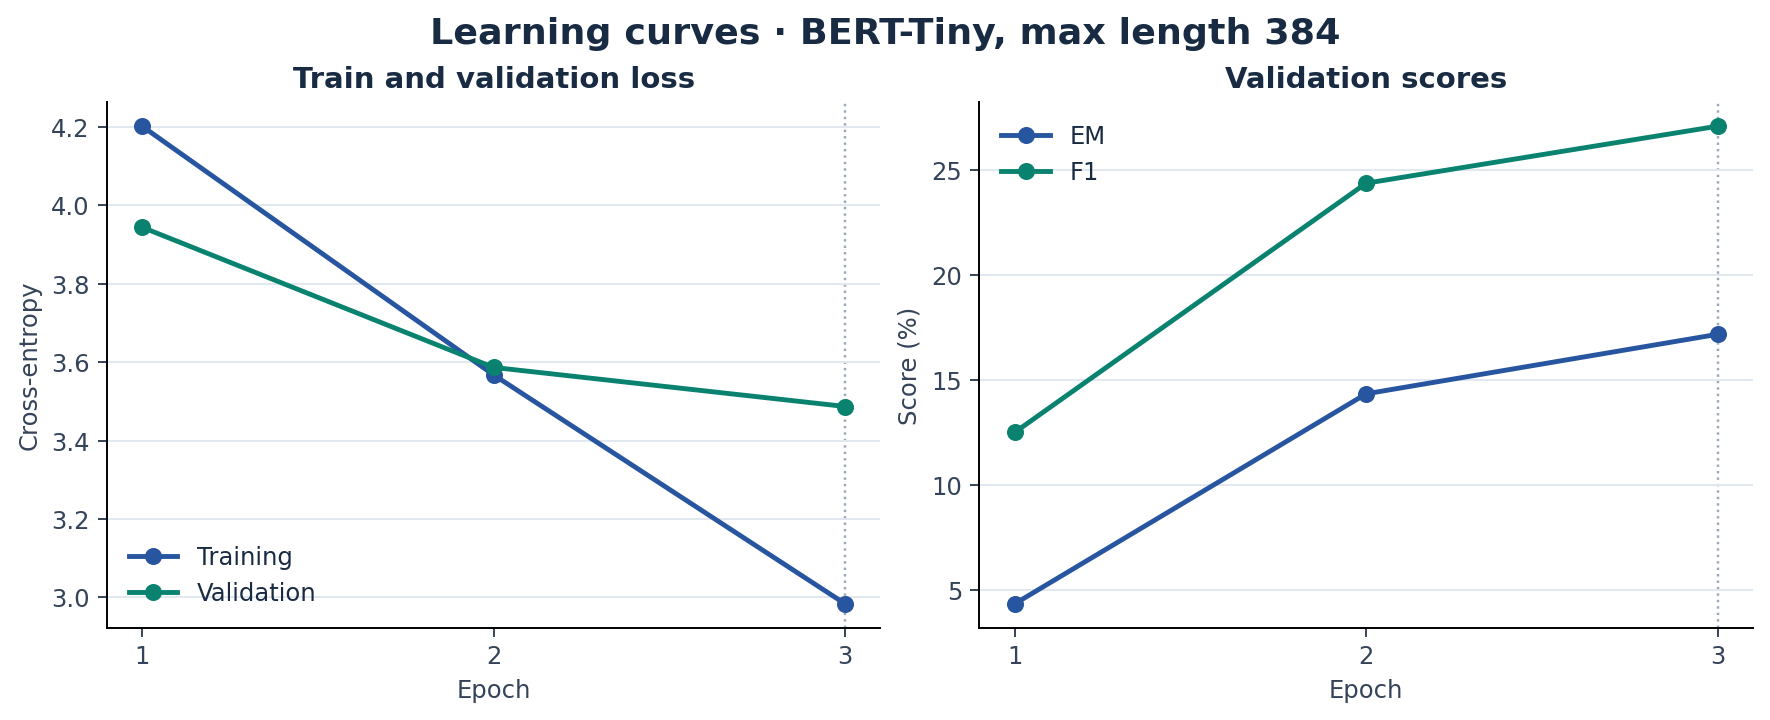

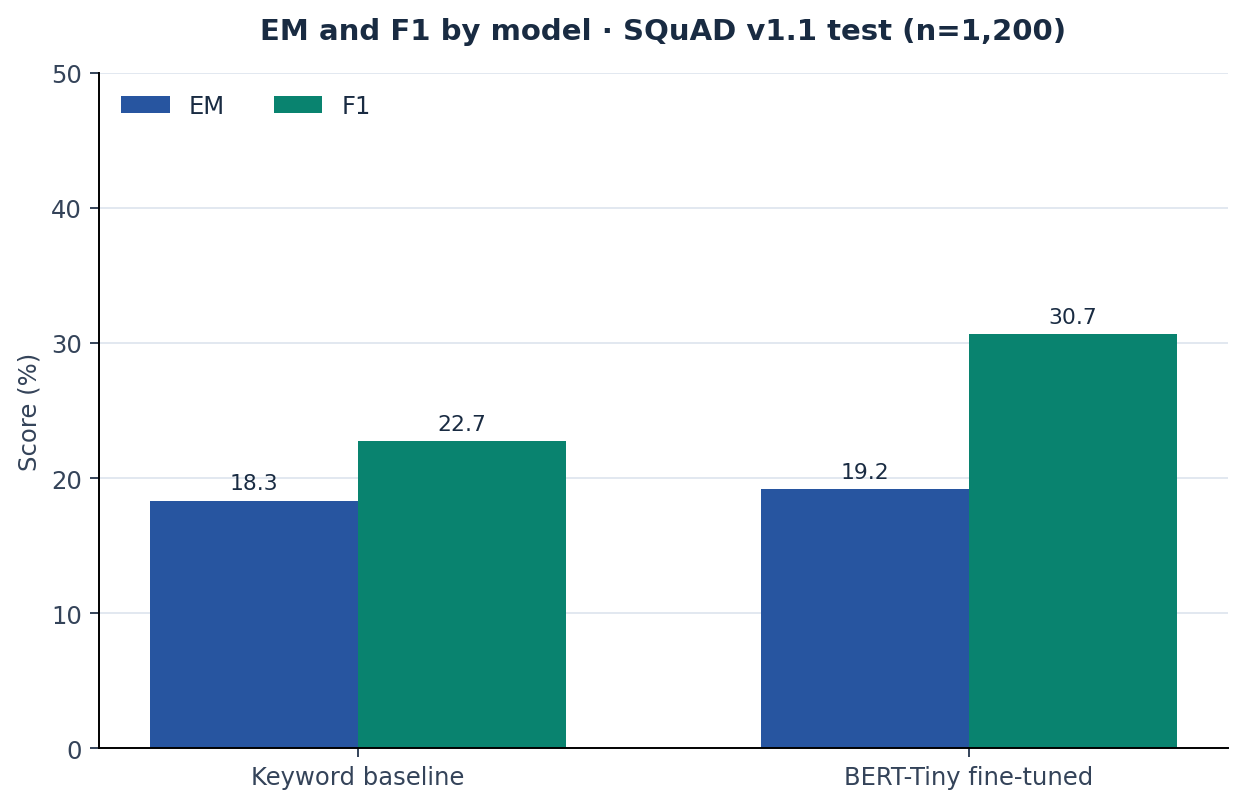

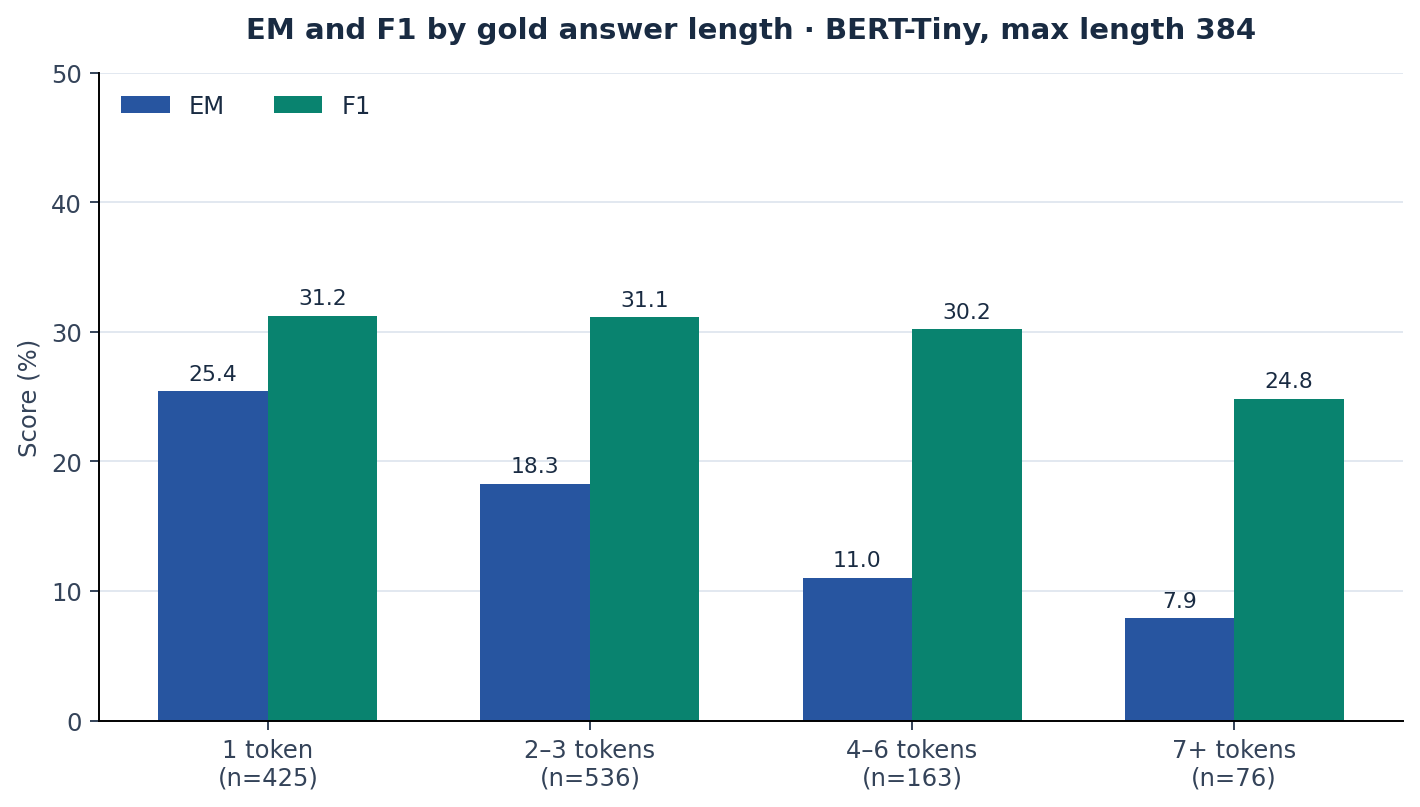

In [10]:
figure, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
figure.suptitle("Learning curves · BERT-Tiny, max length 384", fontsize=15, fontweight="bold")
history = pd.DataFrame(histories[config.max_length])
for metric, label, color in [("train_loss", "Training", blue), ("validation_loss", "Validation", green)]:
    axes[0].plot(history.epoch, history[metric], marker="o", label=label, color=color, linewidth=2)
for metric, color in [("em", blue), ("f1", green)]:
    axes[1].plot(history.epoch, history[metric], marker="o", label=metric.upper(), color=color,
                 linewidth=2)
selected_epoch = int(history.loc[history.f1.idxmax(), "epoch"])
for axis, title, ylabel in zip(axes, ["Train and validation loss", "Validation scores"],
                                ["Cross-entropy", "Score (%)"]):
    axis.set(title=title, xlabel="Epoch", ylabel=ylabel, xticks=history.epoch)
    axis.grid(axis="y")
    axis.axvline(selected_epoch, color="#9aa9b9", linewidth=1, linestyle=":", zorder=0)
    axis.legend(frameon=False)
save_chart(figure, "learning_curves.png")

figure, axis = plt.subplots(figsize=(7, 4.5), layout="constrained")
axis.set_title(f"EM and F1 by model · SQuAD v1.1 test (n={len(test):,})", pad=14)
paired_bars(axis, comparison, ["Keyword baseline", "BERT-Tiny fine-tuned"])
save_chart(figure, "em_f1_analysis.png")

figure, axis = plt.subplots(figsize=(8, 4.5), layout="constrained")
axis.set_title("EM and F1 by gold answer length · BERT-Tiny, max length 384", pad=14)
labels = [f"{row.group} {'token' if row.group == '1' else 'tokens'}\n(n={row.n:,})"
          for row in answer_length_frame.itertuples()]
paired_bars(axis, answer_length_frame, labels)
save_chart(figure, "answer_length_analysis.png")

In [11]:
# Local evidence used to reconcile the report with the run, including per-question offsets.
work.mkdir(exist_ok=True, parents=True)
evidence_path = work / f"evaluation_{profile}.json"
evidence_path.write_text(json.dumps({
    "metadata": meta, "gold_comparison": boundary_rows,
    "condition_predictions": {
        group: {key: asdict(value) for key, value in predictions.items()}
        for group, predictions in condition_predictions.items()
    },
    "demo": [dict(question=question, **asdict(span)) for question, span in zip(DEMO_QUESTIONS, demo_spans)],
}, ensure_ascii=False, indent=2), encoding="utf-8")
assert len(result_frame) == len(lengths) + len(eval_rows) + len(comparison) + len(matching_rows) + len(answer_length_frame) + len(boundary_metrics)
print(f"Exported {len(result_frame)} measured rows and three charts.")

Exported 29 measured rows and three charts.
